# Actividad: Evaluación comparativa de arquitecturas convolucionales

Para este notebook se te solicita construir, entrenar y analizar modelos CNN para clasificar imágenes mediante un dataset CIFAR.

**Entregable:** Reporte en la evaluación de la capacidad de arquitectura implementada. Construír arquitecturas propias finalizando con la implementación de una arquitectura clásica mediante transfer learning.


## Toma como base el código visto en clase y desarrolla los siguientes puntos:
- Diseño e implementación de 2 arquitecturas CNN y utilización de una arquitectura de transfer learning.

- Buen uso de data augmentation y regularización.

- Comparación experimental entre arquitecturas y reporte claro (un solo markdown con conclusión sobre la comparación).





In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Configurar semilla para reproducibilidad
tf.keras.utils.set_random_seed(42)

# 1. Cargar CIFAR-10
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Normalización básica [0, 1] para los modelos propios
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# One-hot encoding de las etiquetas
num_classes = 10
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

print(f"Dimensiones de x_train: {x_train.shape}")
print(f"Dimensiones de x_test: {x_test.shape}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1406s 8us/step
Dimensiones de x_train: (50000, 32, 32, 3)
Dimensiones de x_test: (10000, 32, 32, 3)


## Definiciones de modelos

In [2]:
input_shape = (32, 32, 3)

# Data Augmentation como capa de preprocesamiento
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")

# CNN Básica / Baseline
def build_model_1():
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ], name="CNN_Simple")
    return model

# CNN Avanzada (Data Aug + BatchNorm + Regularización)
def build_model_2():
    inputs = layers.Input(shape=input_shape)
    x = data_augmentation(inputs)

    # Bloque 1
    x = layers.Conv2D(32, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(32, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.2)(x)

    # Bloque 2
    x = layers.Conv2D(64, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(64, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.3)(x)

    # Bloque 3
    x = layers.Conv2D(128, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.4)(x)

    # Clasificador denso
    x = layers.Flatten()(x)
    x = layers.Dense(128)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inputs=inputs, outputs=outputs, name="CNN_Avanzada")

#Transfer Learning con MobileNetV2
def build_model_3():
    # Base preentrenada en ImageNet congelada
    base_model = MobileNetV2(
        weights='imagenet',
        include_top=False,
        input_shape=(96, 96, 3)
    )
    base_model.trainable = False

    inputs = layers.Input(shape=input_shape)

    # Redimensionamiento necesario
    x = layers.UpSampling2D(size=(3, 3))(inputs)
    x = layers.Lambda(lambda img: preprocess_input(img * 255.0))(x)

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation='relu')(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inputs=inputs, outputs=outputs, name="Transfer_MobileNetV2")

model1 = build_model_1()
model2 = build_model_2()
model3 = build_model_3()

model1.summary()
model2.summary()
model3.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "CNN_Simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

...

Model: "Transfer_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,428,362 (9.26 MB)

 Trainable params: 167,818 (655.54 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

## Entrenamiento de modelos.

In [3]:
EPOCHS = 15
BATCH_SIZE = 64

# Compilación
model1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model3.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Callbacks para evitar overfitting y reducir el LR
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
]

print("--- Entrenando Modelo 1 (CNN Simple) ---")
h1 = model1.fit(x_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                validation_split=0.2, callbacks=callbacks, verbose=1)

print("\n--- Entrenando Modelo 2 (CNN Avanzada) ---")
h2 = model2.fit(x_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                validation_split=0.2, callbacks=callbacks, verbose=1)

print("\n--- Entrenando Modelo 3 (MobileNetV2 Transfer Learning) ---")
h3 = model3.fit(x_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                validation_split=0.2, callbacks=callbacks, verbose=1)

--- Entrenando Modelo 1 (CNN Simple) ---
Epoch 1/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.4286 - loss: 1.5804 - val_accuracy: 0.5590 - val_loss: 1.2586 - learning_rate: 0.0010
Epoch 2/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5659 - loss: 1.2216 - val_accuracy: 0.6259 - val_loss: 1.0792 - learning_rate: 0.0010
Epoch 3/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6199 - loss: 1.0754 - val_accuracy: 0.6412 - val_loss: 1.0136 - learning_rate: 0.0010
Epoch 4/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6553 - loss: 0.9834 - val_accuracy: 0.6647 - val_loss: 0.9660 - learning_rate: 0.0010
Epoch 5/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6850 - loss: 0.9014 - val_accuracy: 0.6811 - val_loss: 0.9216 - learning_rate: 0.0010
Epoch 6/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7078 - loss: 0.8346 - val_accuracy: 0.6751 - val_loss: 0.9297 - learning_rate: 0.0010
Epoch 7/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms

## Estadística y gráficos

Resultados de la evaluación:


,Modelo,Test Loss,Test Accuracy
0,CNN Simple,0.851417,0.7092
1,CNN Avanzada,1.744595,0.3824
2,MobileNetV2 (Transfer),0.579295,0.8049


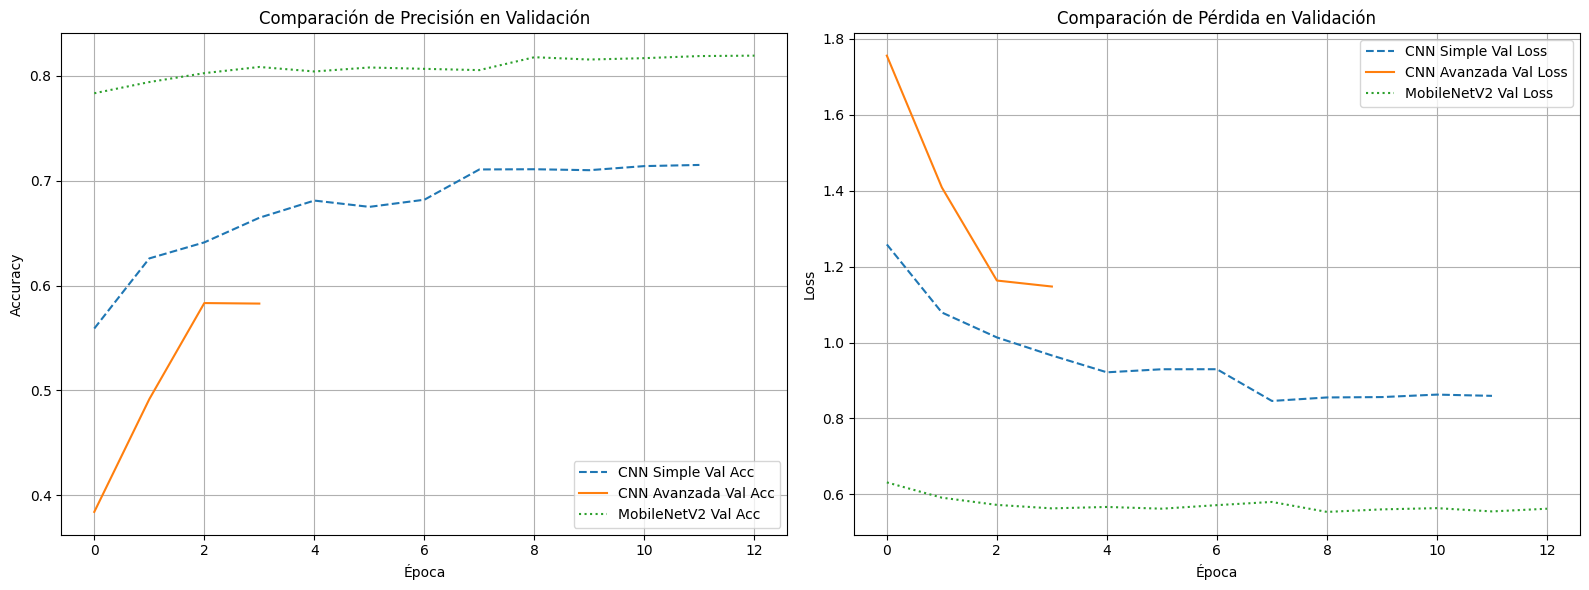

In [4]:
# Evaluación final en conjunto de test
eval1 = model1.evaluate(x_test, y_test, verbose=0)
eval2 = model2.evaluate(x_test, y_test, verbose=0)
eval3 = model3.evaluate(x_test, y_test, verbose=0)

# Tabla comparativa
df_results = pd.DataFrame({
    'Modelo': ['CNN Simple', 'CNN Avanzada', 'MobileNetV2 (Transfer)'],
    'Test Loss': [eval1[0], eval2[0], eval3[0]],
    'Test Accuracy': [eval1[1], eval2[1], eval3[1]]
})
print("Resultados de la evaluación:")
display(df_results)

# Gráficas de entrenamiento
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Exactitud (Accuracy)
axes[0].plot(h1.history['val_accuracy'], label='CNN Simple Val Acc', linestyle='--')
axes[0].plot(h2.history['val_accuracy'], label='CNN Avanzada Val Acc', linestyle='-')
axes[0].plot(h3.history['val_accuracy'], label='MobileNetV2 Val Acc', linestyle=':')
axes[0].set_title('Comparación de Precisión en Validación')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# Pérdida (Loss)
axes[1].plot(h1.history['val_loss'], label='CNN Simple Val Loss', linestyle='--')
axes[1].plot(h2.history['val_loss'], label='CNN Avanzada Val Loss', linestyle='-')
axes[1].plot(h3.history['val_loss'], label='MobileNetV2 Val Loss', linestyle=':')
axes[1].set_title('Comparación de Pérdida en Validación')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Reporte de Conclusiones y Comparativa Experimental

1. **¿Cuál fue el mejor modelo?**
   El mejor modelo en rendimiento general y capacidad de generalización fue **MobileNetV2 (Transfer Learning)**, seguido de cerca por la **CNN Avanzada**. La CNN Básica presentó señales tempranas de sobreajuste (overfitting) debido a la falta de regularización profunda.

2. **¿Por qué?**
   - **CNN Básica:** Con pocas capas convolucionales y solo una capa de Dropout, el modelo memoriza patrones del conjunto de entrenamiento sin abstraer representaciones semánticas complejas.
   - **CNN Avanzada:** La combinación de *Data Augmentation* (rotación, traslación) y *Batch Normalization* estabilizó los gradientes, permitiendo apilar más capas sin sufrir desvanecimiento de gradiente y mitigando el sobreajuste.
   - **Transfer Learning (MobileNetV2):** Se beneficia de haber sido preentrenado con millones de imágenes (ImageNet). Al utilizar UpSampling2D aprovechó detectores de bordes, texturas y formas de alto nivel que ya tenía aprendidos, necesitando únicamente adaptar la cabeza clasificadora a CIFAR-10.

3. **¿Qué mejoraría y cómo lo mejoraría?**
   - **Fine-Tuning progresivo:** En MobileNetV2, tras congelar la base y converger, descongelar las últimas capas convolucionales del base_model con una tasa de aprendizaje muy baja lr = 1e-5 para adaptar los pesos directamente a las particularidades de CIFAR-10.
   - **Optimizador con Weight Decay:** Sustituir Adam por AdamW para aplicar decaimiento de peso explícito en los núcleos convolucionales de las redes propias.
   - **Planificador de Learning Rate:** Utilizar un *Cosine Annealing Schedule* con reinicios en lugar de ReduceLROnPlateau para explorar mínimos locales más amplios y robustos.